<a href="https://colab.research.google.com/github/Charanca24/Team-E/blob/main/flu_vaccine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Flu Vaccine Cost Challenge – Dataset A
# Goal: decide who to send a seasonal flu vaccine to, so the town's total expected cost (vaccines + hospitalisations) is as low as possible.

In [3]:
REPO_URL = "https://github.com/Charanca24/Team-E.git"
DATA_DIR = "Team-E"
!git clone {REPO_URL}

Cloning into 'Team-E'...
remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 5 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (5/5), 190.82 KiB | 4.34 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.calibration import calibration_curve

SEED = 42
train = pd.read_csv(f"{DATA_DIR}/dataset_A_training (1).csv", index_col="respondent_id")
test  = pd.read_csv(f"{DATA_DIR}/dataset_A_testing.csv",     index_col="respondent_id")
TARGET = "seasonal_vaccine"
X, y = train.drop(columns=TARGET), train[TARGET]
print("train:", X.shape, " test:", test.shape)

train: (4756, 29)  test: (4749, 29)


## 2. Exploratory Data Analysis

seasonal_vaccine
1    0.536
0    0.464
Name: proportion, dtype: float64


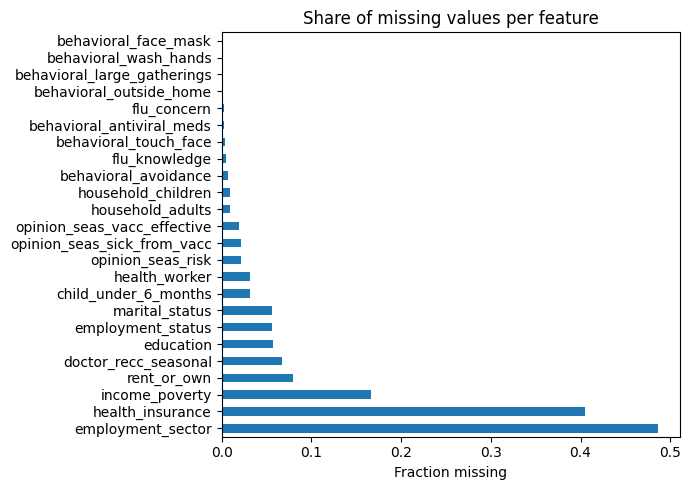

In [6]:
# Target balance: ~54% accept the vaccine, so classes are roughly balanced
print(y.value_counts(normalize=True).round(3))

# Missing values per feature
miss = X.isna().mean().sort_values(ascending=False)
miss[miss > 0].plot(kind="barh", figsize=(7, 5), title="Share of missing values per feature")
plt.xlabel("Fraction missing"); plt.tight_layout(); plt.show()

**Observation:** employment_sector (~49%) and health_insurance (~40%) are heavily missing. Instead of dropping them, we impute with a "missing" category/indicator, because not answering may itself be predictive.

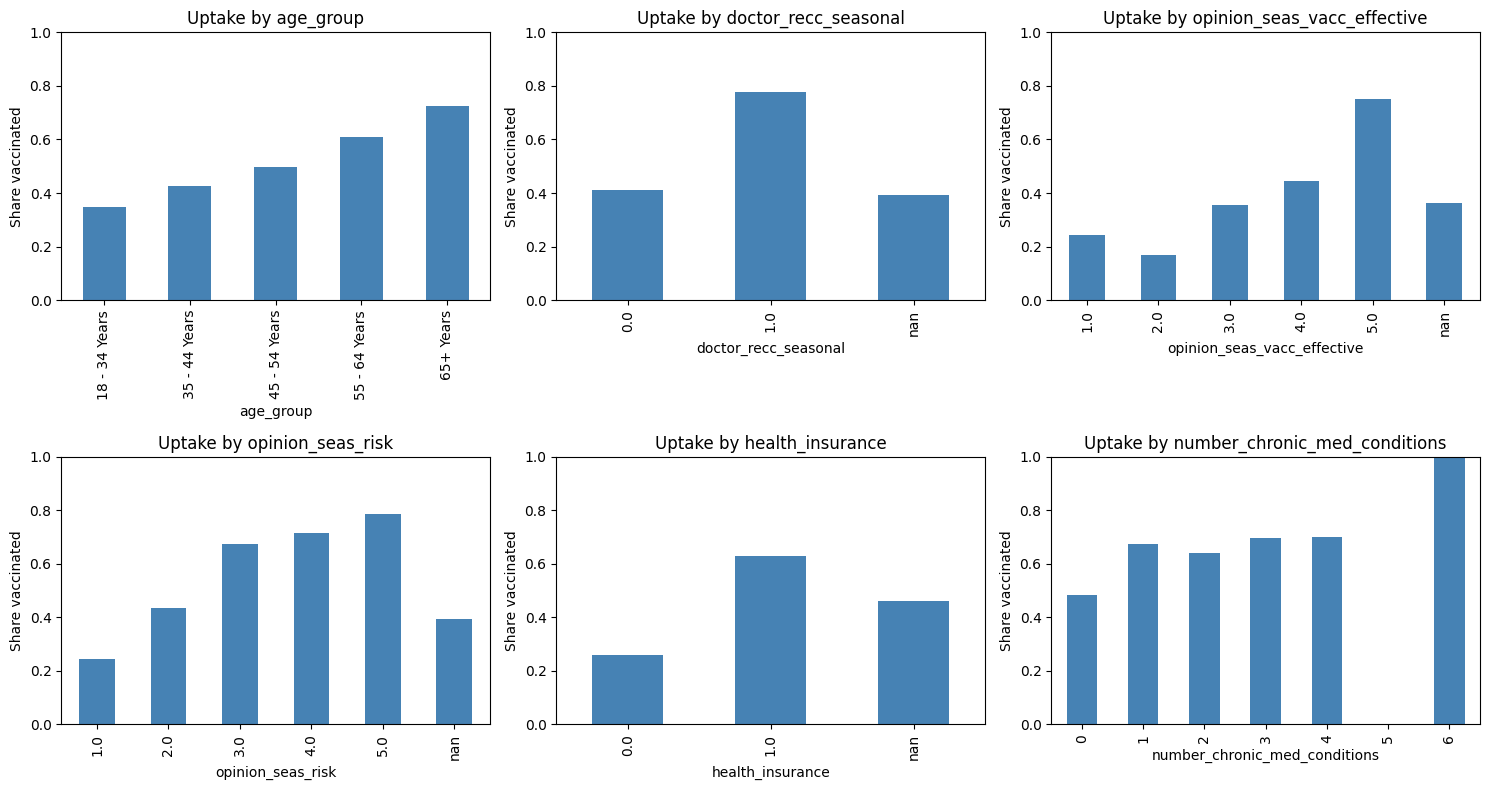

In [7]:
key_cols = ["age_group", "doctor_recc_seasonal", "opinion_seas_vacc_effective",
            "opinion_seas_risk", "health_insurance", "number_chronic_med_conditions"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_cols):
    train.groupby(col, dropna=False)[TARGET].mean().plot(kind="bar", ax=ax, color="steelblue")
    ax.set_title(f"Uptake by {col}"); ax.set_ylabel("Share vaccinated"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Observation:** uptake rises steeply with age (35% for 18–34 vs 73% for 65+), and with doctor recommendation, belief that the vaccine works, and perceived risk.

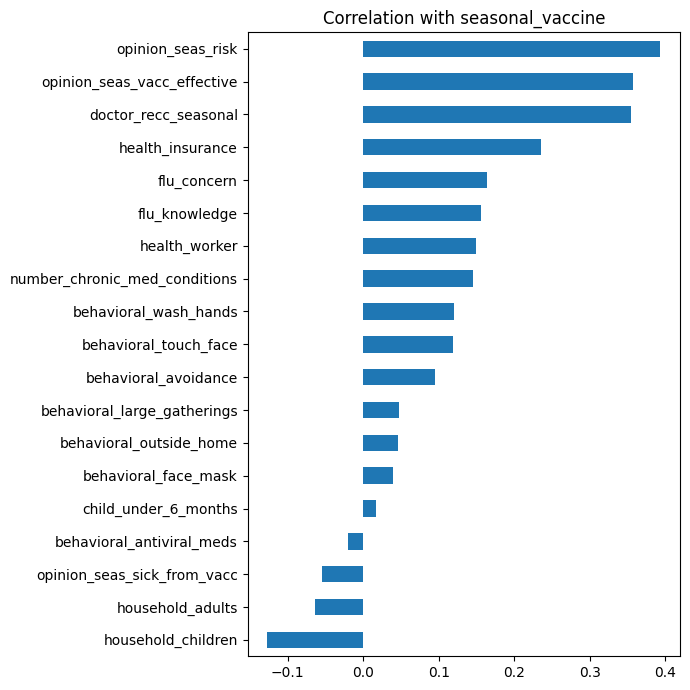

In [8]:
num = train.select_dtypes("number")
num.corr()[TARGET].drop(TARGET).sort_values().plot(kind="barh", figsize=(7, 7),
                                                   title="Correlation with seasonal_vaccine")
plt.tight_layout(); plt.show()